# 8. Steepest descent and saddle points

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 6 and 7, complex variables

Laplace's method needs a real exponent with a maximum; stationary phase needs a purely
imaginary one. Many integrals have neither: the exponent is complex, or the integral
is defined along a contour in the complex plane, as for the Airy function, inverse
Laplace transforms and the Fourier transforms of smooth functions. The **method of
steepest descent** (Debye, 1909) unifies the two. One deforms the contour, as
Cauchy's theorem allows, so that it passes through a **saddle point** of the
exponent along the direction in which the real part falls fastest. On that path the
imaginary part of the exponent is constant, there is no oscillation, and the
integral becomes a Laplace integral.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 60

## 8.1 Saddle points and steepest paths

Consider $I(\lambda) = \int_C g(z)\,e^{\lambda f(z)}\,\mathrm dz$ with $f$ analytic.
Write $f = u + iv$. The size of the integrand is set by $u$, its oscillation by
$v$. Because $f$ is analytic, $u$ has no maxima or minima in the plane, only
**saddles**, where $f'(z_0) = 0$. Through a saddle there pass two special curves on
which $v$ is constant: along one, $u$ decreases from $z_0$ as fast as possible (the
path of steepest descent); along the other it increases. The steepest-descent path
is also the path on which the integrand does not oscillate, since $v$ is constant.

The recipe is therefore:

1. find the saddle points $f'(z_0) = 0$;
2. deform the contour into steepest-descent paths through the relevant saddles
   (which saddles are relevant is decided by the topology of the paths and the
   endpoints of the contour, and is the only delicate step);
3. on each path apply Laplace's method: with $f''(z_0) = |f''|e^{i\phi}$, the
   path leaves $z_0$ at the angle $\theta = (\pi - \phi)/2$ (or $\theta + \pi$), and

$$ I(\lambda) \sim g(z_0)\,e^{\lambda f(z_0)}\sqrt{\frac{2\pi}{\lambda|f''(z_0)|}}\;e^{i\theta} . $$

Laplace's method ($\phi = \pi$, $\theta = 0$) and stationary phase
($\phi = \pm\pi/2$, $\theta = \pm\pi/4$ up to orientation) are special cases.

## 8.2 The Airy function

The Airy function solves $y'' = xy$, the equation of a quantum particle near a
classical turning point, of light near a caustic, and of the front of a dispersive wave
train. Its integral representation is

$$ \operatorname{Ai}(x) = \frac{1}{2\pi i}\int_C e^{t^3/3 - xt}\,\mathrm dt , $$

with $C$ coming in from infinity along $\arg t = -\pi/3$ and leaving along
$\arg t = +\pi/3$. For large $|x|$, put $t = |x|^{1/2}s$ and $\lambda = |x|^{3/2}$:
the exponent becomes $\lambda f(s)$ with $f(s) = s^3/3 \mp s$ for $x \gtrless 0$.

**$x > 0$.** The saddles are at $s = \pm 1$, with $f(1) = -2/3$ and $f''(1) = 2$. On
the real axis $s = 1$ is a minimum of $f$, so the steepest-descent direction is
vertical ($\phi = 0$, $\theta = \pi/2$). The path is the branch of the hyperbola
$u^2 - v^2/3 = 1$ (in $s = u + iv$) through $s = 1$, whose asymptotes are exactly the
directions $\pm\pi/3$ of $C$: the contour can be deformed onto it, and only this saddle
contributes. With $\zeta = \tfrac23 x^{3/2}$,

$$ \operatorname{Ai}(x) \sim \frac{e^{-\zeta}}{2\sqrt\pi\,x^{1/4}}
   \left(1 - \frac{5}{72\zeta} + \frac{385}{10368\,\zeta^2} - \dots\right) . $$

The correction terms come from carrying Laplace's method on the path to higher
order (the coefficients are tabulated in DLMF, Section 9.7).

**$x < 0$.** Now $f(s) = s^3/3 + s$ and the saddles are at $s = \pm i$, both on the
contour's way. Each contributes a term of modulus $|x|^{-1/4}/(2\sqrt\pi)$ and phase
$\pm(\zeta - \pi/4)$, and together

$$ \operatorname{Ai}(-|x|) \sim \frac{1}{\sqrt\pi\,|x|^{1/4}}\sin\!\left(\zeta + \frac\pi4\right) . $$

The function decays exponentially on one side and oscillates on the other: the
classically forbidden and allowed regions of a quantum particle. Near $x = 0$ the
two saddles move together and merge; there, neither formula holds, and the Airy
function is itself the uniform description. The same function connects WKB
solutions across a turning point, a topic of the companion book on perturbation
methods.

In [2]:
xs = np.logspace(0, 2, 25)
zeta = 2 / 3 * xs**1.5
ai_scaled = np.array([float(mp.airyai(x) * mp.exp(mp.mpf(2) / 3 * mp.mpf(x) ** 1.5)) for x in xs])
lead = 1 / (2 * math.sqrt(math.pi) * xs**0.25)
ai_err = {1: np.abs(lead / ai_scaled - 1),
          2: np.abs(lead * (1 - 5 / (72 * zeta)) / ai_scaled - 1),
          3: np.abs(lead * (1 - 5 / (72 * zeta) + 385 / (10368 * zeta**2)) / ai_scaled - 1)}
for N in (1, 2, 3):
    s, p = am.loglog_slope(zeta, ai_err[N], fit_range=(50, 700))
    print(f"Ai(x), x > 0, {N} term(s): relative error ~ {p:.4g} zeta^{s:.3f}")
print(f"(predicted coefficients 5/72 = {5 / 72:.4f}, 385/10368 = {385 / 10368:.4f})")
for x in (1.0, 2.0, 5.0):
    print(f"x = {x}: Ai = {float(mp.airyai(x)):.6e}, leading saddle term {math.exp(-2 / 3 * x**1.5) / (2 * math.sqrt(math.pi) * x**0.25):.6e}")
xneg = np.linspace(2, 12, 400)
neg_err = np.abs(np.sin(2 / 3 * xneg**1.5 + np.pi / 4) / (np.sqrt(np.pi) * xneg**0.25) - am.mp_map(lambda x: mp.airyai(-x), xneg))
print(f"Ai(-x), largest error of the two-saddle formula for 2 < x < 12: {neg_err.max():.4f}  (amplitude at x = 2: {1 / (math.sqrt(math.pi) * 2**0.25):.3f})")

Ai(x), x > 0, 1 term(s): relative error ~ 0.06831 zeta^-0.997
Ai(x), x > 0, 2 term(s): relative error ~ 0.0359 zeta^-1.995
Ai(x), x > 0, 3 term(s): relative error ~ 0.0361 zeta^-2.992
(predicted coefficients 5/72 = 0.0694, 385/10368 = 0.0371)
x = 1.0: Ai = 1.352924e-01, leading saddle term 1.448323e-01
x = 2.0: Ai = 3.492413e-02, leading saddle term 3.599350e-02
x = 5.0: Ai = 1.083444e-04, leading saddle term 1.092981e-04
Ai(-x), largest error of the two-saddle formula for 2 < x < 12: 0.0129  (amplitude at x = 2: 0.474)


On the decaying side the expansion behaves as predicted in the variable $\zeta$:
each term gains a factor $1/\zeta$, with the coefficients of the series. Even at
$x = 1$, where $\zeta$ is only $2/3$, the leading saddle-point term is within 7 %.

## 8.3 Exponentially small Fourier tails

The Fourier transform of a smooth, rapidly decaying function falls faster than any
power of the frequency $k$. Integration by parts gives zero at every order, and
stationary phase finds no real stationary point: both methods can only say that
the result is smaller than any power. Steepest descent finds it. Take

$$ F(k) = \int_{-\infty}^{\infty} e^{-t^4 + ikt}\,\mathrm dt , \qquad k \to \infty , $$

the shape of, for example, the Fourier spectrum of a smooth pulse. The saddles of
$f(t) = -t^4 + ikt$ satisfy $t^3 = ik/4$; the two that the real axis can be deformed
onto are $t_\pm = r\,e^{i\pi/6}$ and $r\,e^{5i\pi/6}$, with $r = (k/4)^{1/3}$. At these
points $f = 3t_\pm^4$, whose real part is $-\tfrac32 r^4$, and $f'' = -12t_\pm^2$. The two
contributions are complex conjugates, and

$$ F(k) \sim 2\,\mathrm{Re}\left[\sqrt{\frac{2\pi}{12\,t_+^2}}\;e^{3t_+^4}\right]
   \propto \exp\!\left[-\tfrac32\left(\tfrac{k}{4}\right)^{4/3}\right]
   \cos\!\left[\tfrac{3\sqrt3}{2}\left(\tfrac{k}{4}\right)^{4/3} - \tfrac\pi6\right] . $$

The transform decays like the exponential of a fractional power of $k$, and it
oscillates: it has zeros. The exact values need high precision, since at $k = 40$ the
result is about $3\times10^{-15}$ while the integrand is of order 1, so the quadrature
must cancel fifteen digits.

In [3]:
def F_exact(k):
    k = mp.mpf(k)
    return 2 * mp.quad(lambda t: mp.exp(-t**4) * mp.cos(k * t), mp.linspace(0, 8, 41))


def F_saddle(k):
    r = (k / 4) ** (1 / 3)
    tp = r * np.exp(1j * np.pi / 6)
    return 2 * np.real(np.sqrt(2 * np.pi / (12 * tp**2)) * np.exp(3 * tp**4))


ks = np.linspace(4, 40, 200)
Fk = np.array([float(F_exact(k)) for k in ks])
Fs = F_saddle(ks)
envelope = 2 * np.abs(np.sqrt(2 * np.pi / (12 * ((ks / 4) ** (1 / 3) * np.exp(1j * np.pi / 6)) ** 2))) * np.exp(-1.5 * (ks / 4) ** (4 / 3))
rel = np.abs(Fk - Fs) / envelope
for k in (10, 20, 30, 40):
    i = np.argmin(np.abs(ks - k))
    print(f"k = {k}: F = {Fk[i]: .4e}, saddle points {Fs[i]: .4e}, error / envelope {rel[i]:.4f}")
s, p = am.loglog_slope(ks, rel, fit_range=(15, 40))
print(f"error / envelope ~ {p:.3g} k^{s:.2f}   (expected exponent -4/3 = {-4 / 3:.2f}: the first correction is O(1/r^4))")

k = 10: F = -2.5357e-03, saddle points -2.6281e-03, error / envelope 0.0138
k = 20: F = -2.2203e-06, saddle points -2.2316e-06, error / envelope 0.0046
k = 30: F =  1.9180e-10, saddle points  1.9212e-10, error / envelope 0.0017
k = 40: F =  2.8066e-15, saddle points  2.8205e-15, error / envelope 0.0022
error / envelope ~ 0.128 k^-1.28   (expected exponent -4/3 = -1.33: the first correction is O(1/r^4))


The two saddle points reproduce the transform, its decay and its zeros, over
fourteen orders of magnitude. The error, measured relative to the envelope of the
result, falls roughly as $k^{-4/3}$, the order of the first correction in this
problem (Laplace's method on each path, with $\lambda f'' \propto r^4$); the fitted
exponent, $-1.28$, is less precise than usual because the error oscillates too. An integral that real
methods could only bound has been evaluated, because its value is decided at points
that lie off the real axis.

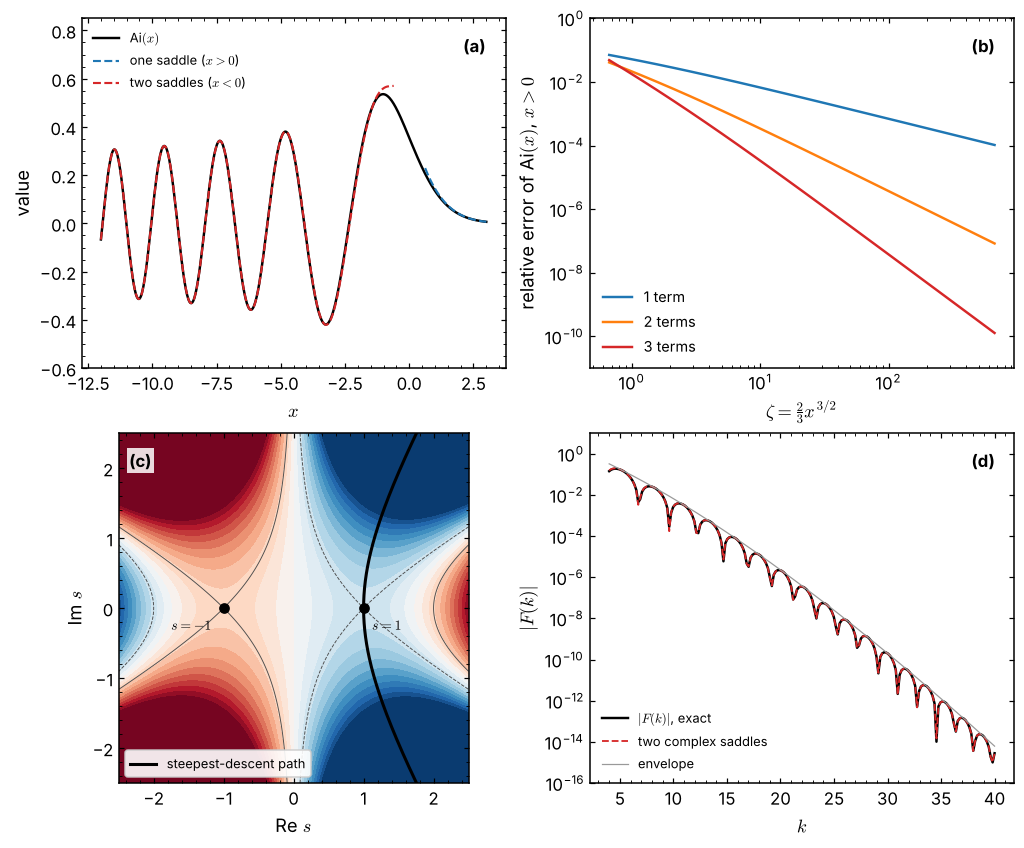

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
xa = np.linspace(-12, 3, 600)
ax.plot(xa, am.mp_map(mp.airyai, xa), "k", lw=1.6, label=r"Ai$(x)$")
xp = xa[xa > 0.6]
ax.plot(xp, np.exp(-2 / 3 * xp**1.5) / (2 * np.sqrt(np.pi) * xp**0.25), "C0--", lw=1.4, label="one saddle ($x > 0$)")
xm = -xa[xa < -0.6]
ax.plot(-xm, np.sin(2 / 3 * xm**1.5 + np.pi / 4) / (np.sqrt(np.pi) * xm**0.25), "C3--", lw=1.4, label="two saddles ($x < 0$)")
ax.set_xlabel("$x$"); ax.set_ylabel("value")
ax.set_ylim(-0.6, 0.85); ax.legend(loc="upper left", fontsize=8.5); am.panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
for N, c in zip((1, 2, 3), ("C0", "C1", "C3")):
    ax.loglog(zeta, ai_err[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel(r"$\zeta = \frac{2}{3}x^{3/2}$"); ax.set_ylabel(r"relative error of Ai$(x)$, $x > 0$")
ax.set_ylim(1e-11, 1); ax.legend(loc="lower left"); am.panel_label(ax, "(b)", x=0.9)

ax = axes[1, 0]
U, V = np.meshgrid(np.linspace(-2.5, 2.5, 400), np.linspace(-2.5, 2.5, 400))
S = U + 1j * V
re_f = np.real(S**3 / 3 - S)
cs = ax.contourf(U, V, np.clip(re_f, -3, 3), levels=np.linspace(-3, 3, 25), cmap="RdBu_r")
ax.contour(U, V, re_f, levels=[-2 / 3, 2 / 3], colors="0.3", linewidths=0.6)
vv = np.linspace(-2.5, 2.5, 200)
ax.plot(np.sqrt(1 + vv**2 / 3), vv, "k", lw=2, label="steepest-descent path")
ax.plot([1, -1], [0, 0], "ko", ms=6)
ax.text(1.12, -0.32, "$s = 1$", fontsize=9); ax.text(-1.75, -0.32, "$s = -1$", fontsize=9)
ax.set_xlabel(r"Re $s$"); ax.set_ylabel(r"Im $s$"); ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=8.5, frameon=True, framealpha=0.9)
ax.text(0.03, 0.95, "(c)", transform=ax.transAxes, ha="left", va="top", fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))

ax = axes[1, 1]
ax.semilogy(ks, np.abs(Fk), "k", lw=1.6, label=r"$|F(k)|$, exact")
ax.semilogy(ks, np.abs(Fs), "C3--", lw=1.2, label="two complex saddles")
ax.semilogy(ks, envelope, "0.6", lw=0.8, label="envelope")
ax.set_xlabel("$k$"); ax.set_ylabel(r"$|F(k)|$")
ax.set_ylim(1e-16, 10); ax.legend(loc="lower left", fontsize=8.5); am.panel_label(ax, "(d)", x=0.9)
plt.show()

**(a)** The Airy function and its saddle-point approximations on the two sides of the
turning point (not drawn for $|x| < 0.6$, where the saddles merge). **(b)** Relative
error of the expansion for $x > 0$ with one to three terms, against
$\zeta = \tfrac23x^{3/2}$. **(c)** Real part of $f(s) = s^3/3 - s$ (red high, blue low)
with the two saddles and the steepest-descent path through $s = 1$ that the Airy
contour is deformed onto; the thin lines are the level curves of the saddles.
**(d)** The Fourier transform of $e^{-t^4}$ and its two-saddle approximation.

## Summary

* For complex exponents, deform the contour through saddle points of $f$ along the
  paths of steepest descent, on which the integrand does not oscillate; then apply
  Laplace's method.
* Laplace's method and stationary phase are special cases, with the saddle on the
  real axis.
* Which saddles contribute depends on whether the contour can be deformed onto their
  paths; this is the only delicate step.
* Saddles off the real axis decide exponentially small results, such as the tails
  of Fourier transforms, that real methods cannot evaluate.
* When two saddles merge, as at a turning point, the separate formulas fail and a
  uniform approximation (here the Airy function itself) is needed.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* N. Bleistein and R. A. Handelsman, *Asymptotic Expansions of Integrals* (Holt,
  Rinehart and Winston, 1975; Dover, 1986).
* N. G. de Bruijn, *Asymptotic Methods in Analysis*, 3rd ed. (North-Holland, 1970;
  Dover, 1981).
* P. Debye, "Näherungsformeln für die Zylinderfunktionen für große Werte des
  Arguments und unbeschränkt veränderliche Werte des Index", *Math. Ann.* **67**,
  535 (1909).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* F. W. J. Olver, *Asymptotics and Special Functions* (Academic Press, 1974;
  A K Peters, 1997).
* F. W. J. Olver, D. W. Lozier, R. F. Boisvert and C. W. Clark (eds), *NIST Handbook
  of Mathematical Functions* (Cambridge University Press, 2010), online as the
  Digital Library of Mathematical Functions (DLMF), https://dlmf.nist.gov.

## Exercises

1. Sketch the level curves of $\mathrm{Im}\,f$ for $f = s^3/3 + s$ and show that the
   Airy contour for $x < 0$ can be deformed through both saddles $s = \pm i$.
2. Derive the $-5/(72\zeta)$ term of the Airy expansion by carrying Laplace's method
   on the steepest-descent path to the next order.
3. Find the large-$k$ behaviour of the Fourier transform of $1/\cosh t$, whose poles
   at $t = \pm i\pi/2$ take the place of saddles, and compare with the exact result
   $\pi/\cosh(\pi k/2)$.
4. Use steepest descent on Hankel's integral to derive Stirling's formula for
   $1/\Gamma(z)$ with complex $z$.

---

**Previous:** [7. Stationary phase](07_stationary_phase.ipynb) &nbsp;·&nbsp; **Next:** [9. Sums: Euler–Maclaurin and the Stirling series](09_sums_euler_maclaurin_and_stirling.ipynb)